## Dose Prediction: Classic DDPM (conservative optimisation)

135-optimised-arch-2

- AMP training
- bf16 sampling
- Training T=1000
- Optimised Caching
- Sampling DDPM T=4 (not 10)
- Optimised Architecture 2
- No Distillation

## Dose Prediction: Warm Start Diffusion (no)

155-wsd-combi

- same as above, except
- Sampling DDPM T=4

## Dose Prediction: InDI (no)

156-indi-combi

- same as above, except
- Sampling T=2

## Dose Prediction: Flow Matching

157-rfm-combi

- same as above, except
- Sampling T=2

## Dose Prediction: Warm Start Flow Matching

158-ws-rfm-combi

- same as above, except
- Sampling T=2 (or even 1?)

## Dose Calculation: conservative + heavy optimisation

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED, is_higher_better, get_metric_abbr, get_metric_label

In [3]:
dataset = build_dataset('test')

In [11]:
baseline_results = []

for seed in range(1, 11):
  sampling_name = f'ddpm-seed{seed}-1000' if seed > 1 else 'ddpm-1000'
  baseline_results.append(ModelResults('112-beamdiff-bf16', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('136-beamdiff-bf16-2', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('137-beamdiff-bf16-3', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('138-beamdiff-bf16-4', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('139-beamdiff-bf16-5', sampling_name, 199, 'test', dataset))

baseline_comparison = ModelComparison(baseline_results, ['Model 1'] * 10 + ['Model 2'] * 10 + ['Model 3'] * 10 + ['Model 4'] * 10 + ['Model 5'] * 10, ['DDPM'] * 50)

In [4]:
unet_baseline = ModelResults('107-deeplabv3plus', 'unet', 199, 'test', dataset)
ddpm_baseline = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)

ddpm_combi = ModelResults('135-optimised-arch-2', 'ddpm-cache-beamdiff-enc2-interval5-20-200-inf-10-bf16-amp', 199, 'test', dataset)
ddpm_combi_no_cache = ModelResults('135-optimised-arch-2', 'ddpm-10-bf16-amp', 199, 'test', dataset)
ddpm_combi_orig_arch = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval5-20-200-inf-10-bf16-amp', 199, 'test', dataset)

wsd_combi = ModelResults('155-wsd-combi', 'ddpm-cache-beamdiff-enc2-interval5-20-200-inf-4-bf16-amp', 199, 'test', dataset)
indi_combi = ModelResults('156-indi-combi', 'indi-cache-beamdiff-enc2-interval5-20-200-inf-2-bf16-amp', 199, 'test', dataset)
flow_combi = ModelResults('157-rfm-combi', 'flow-cache-beamdiff-enc2-interval5-20-200-inf-2-bf16-amp', 199, 'test', dataset)
ws_flow_combi_2 = ModelResults('158-ws-rfm-combi', 'flow-cache-beamdiff-enc2-interval5-20-200-inf-2-bf16-amp', 199, 'test', dataset)
ws_flow_combi_1 = ModelResults('158-ws-rfm-combi', 'flow-cache-beamdiff-enc2-interval5-20-200-inf-1-bf16-amp', 199, 'test', dataset)


In [5]:
ddpm_combi_comparison = ModelComparison(
  [ddpm_combi, ddpm_combi_no_cache, ddpm_combi_orig_arch, ddpm_baseline],
  ['DDPM Optimised', 'DDPM Optimised (No Cache)', 'DDPM Optimised (Original Arch)', 'DDPM Baseline'],
  ['Optimised'] * 3 + ['Baseline']
)

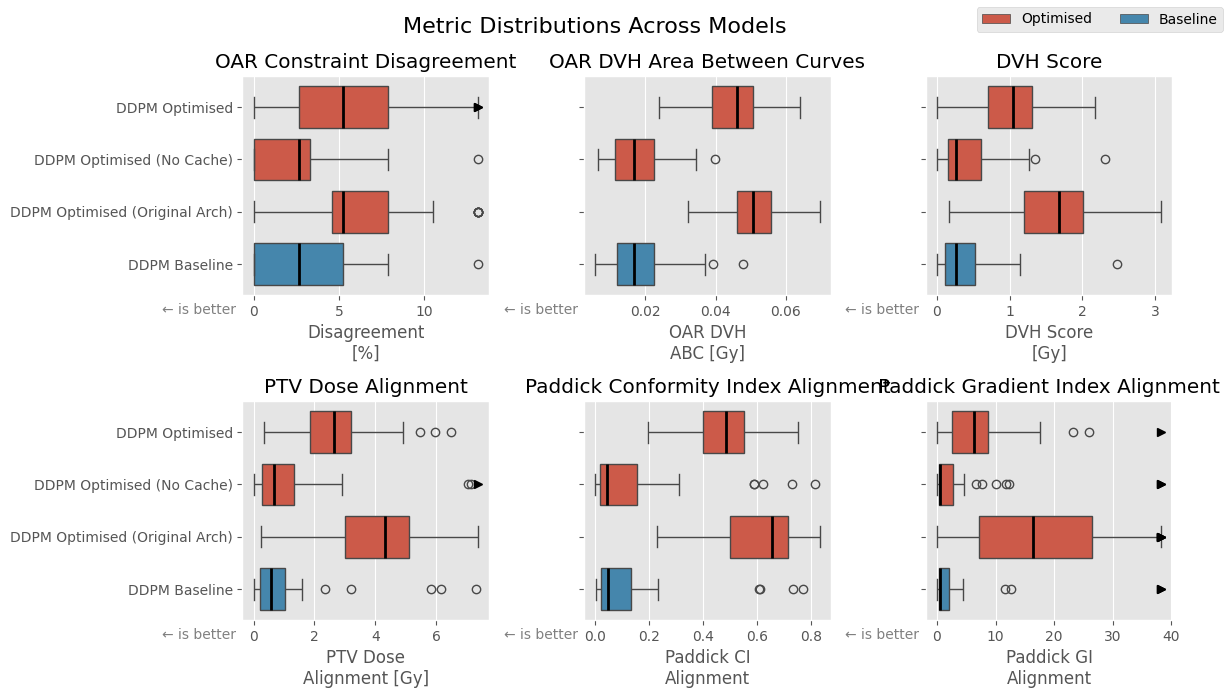

In [6]:
_ = ddpm_combi_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

In [7]:
comparison = ModelComparison(
  [ddpm_combi_no_cache, wsd_combi, indi_combi, flow_combi, ws_flow_combi_2, ws_flow_combi_1, unet_baseline, ddpm_baseline],
  ['DDPM Optimised', 'WSD Optimised', 'InDI Optimised', 'RFM Optimised', 'WS + RFM Optimised (T=2)', 'WS + RFM Optimised (T=1)', 'UNet Baseline', 'DDPM Baseline'],
  ['Optimised'] * 6 + ['Baseline'] * 2
)

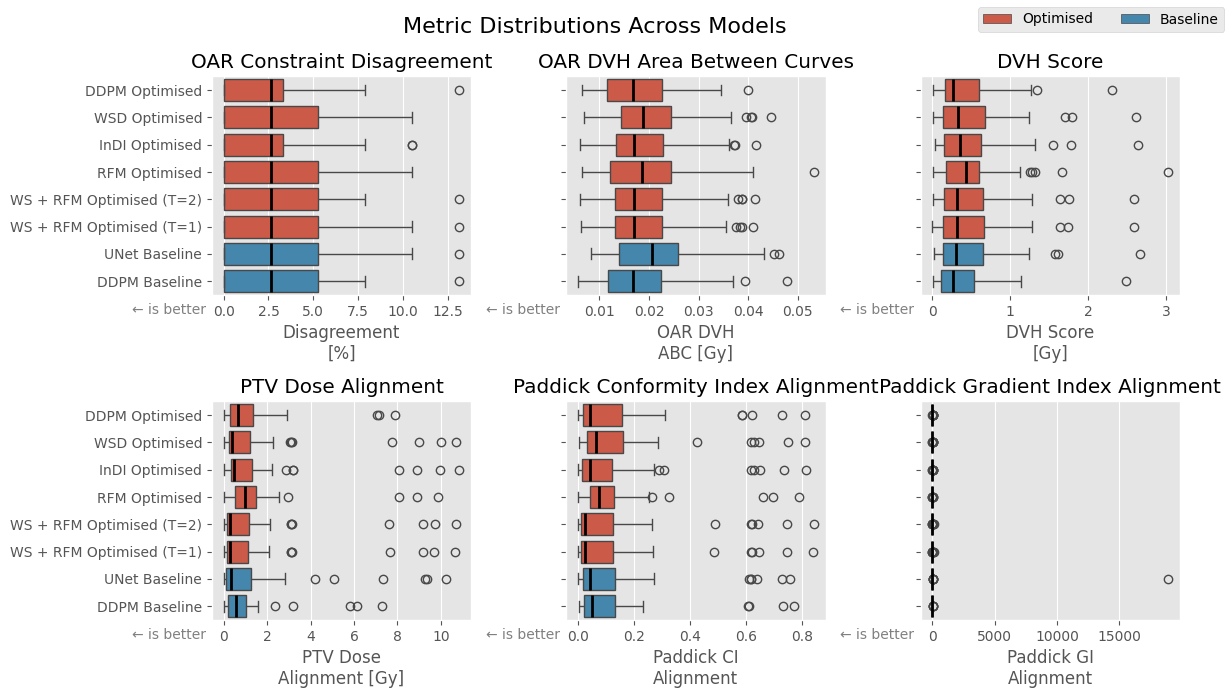

In [16]:
_ = comparison.plot_metric_distributions(METRICS_PRED, outliers=True)

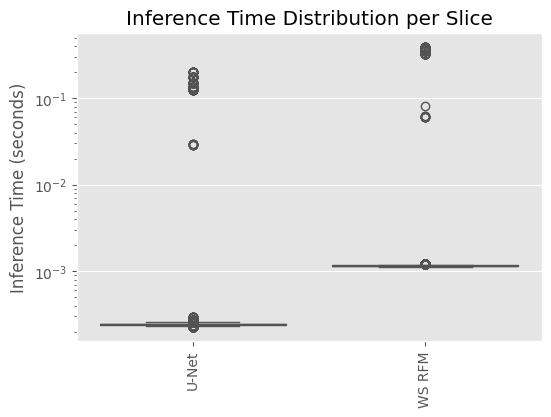

In [9]:
ax = ModelComparison([unet_baseline, ws_flow_combi_1], ['U-Net', 'WS RFM']).plot_inference_times('slice', 'seconds')
ax.set_yscale('log')

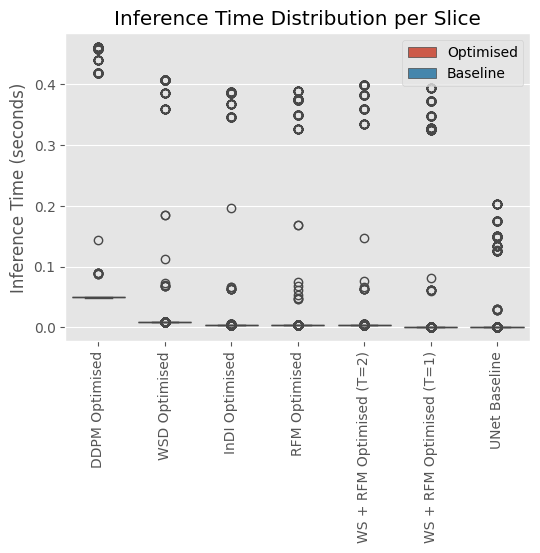

In [10]:
_ = (comparison - ddpm_baseline).plot_inference_times('slice', 'seconds')

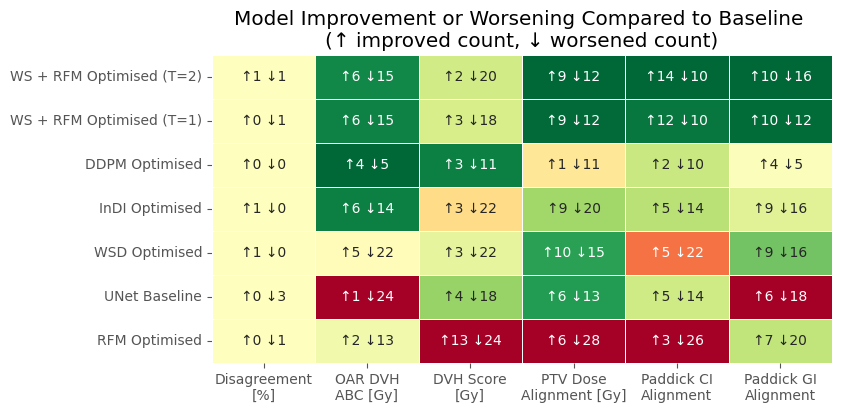

In [17]:
_ = (comparison - ddpm_baseline).plot_metric_heatmap(METRICS_PRED, baseline=baseline_comparison, improved_q=1, worsened_q=0)

In [27]:
baseline_comparison.volume_metrics.groupby('file_name')['vol_dvh'].max()

file_name
0522c0027+A4Ac+MOS_30413        0.306525
0522c0142+A4Ac+MOS_43691        0.427597
0522c0444+A4Ac+MOS_24107        0.122592
0522c0555+A4Ac+MOS_22329        0.083958
0522c0629+A4Ac+MOS_1367         0.869030
0522c0723+A4Ac+MOS_2890         0.271852
HN-CHUM-003+S2A4Ac+MOS_20285    1.002711
HN-CHUM-007+S2A4Ac+MOS_28117    1.065943
HN-CHUM-011+S2A4Ac+MOS_13191    0.961500
HN-CHUM-051+A4Ac+MOS_4095       1.242603
HN-CHUM-053+S2A4Ac+MOS_14660    0.151455
HN-CHUS-089+S2A4Ac+MOS_9626     0.349223
HN-CHUS-102+S2A4Ac+MOS_51735    2.507220
HN-HGJ-009+S2A4Ac+MOS_16685     0.217113
HN-HGJ-064+S2A4Ac+MOS_40817     0.399993
HN-HGJ-074+S2A4Ac+MOS_10993     0.065636
HN-HGJ-080+S2A4Ac+MOS_55964     0.474283
HNC_004+A4Ac+MOS_11506          0.194333
HNC_030+A4Ac+MOS_3259           0.139600
HNC_031+A4Ac+MOS_58298          0.235469
HNC_034+A4Ac+MOS_55214          0.082909
HNC_053+A4Ac+MOS_6535           0.265493
HNC_095+A4Ac+MOS_22308          0.252940
HNC_107+A4Ac+MOS_49283          0.582746
HNC_11

In [25]:
comparison.volume_metrics.groupby('file_name')['vol_dvh'].min()

file_name
0522c0027+A4Ac+MOS_30413        0.129326
0522c0142+A4Ac+MOS_43691        0.185509
0522c0444+A4Ac+MOS_24107        0.004395
0522c0555+A4Ac+MOS_22329        0.013201
0522c0629+A4Ac+MOS_1367         0.765982
0522c0723+A4Ac+MOS_2890         0.033211
HN-CHUM-003+S2A4Ac+MOS_20285    0.810226
HN-CHUM-007+S2A4Ac+MOS_28117    0.874592
HN-CHUM-011+S2A4Ac+MOS_13191    0.718287
HN-CHUM-051+A4Ac+MOS_4095       0.975052
HN-CHUM-053+S2A4Ac+MOS_14660    0.100764
HN-CHUS-089+S2A4Ac+MOS_9626     0.023792
HN-CHUS-102+S2A4Ac+MOS_51735    2.311239
HN-HGJ-009+S2A4Ac+MOS_16685     0.056040
HN-HGJ-064+S2A4Ac+MOS_40817     0.008797
HN-HGJ-074+S2A4Ac+MOS_10993     0.039069
HN-HGJ-080+S2A4Ac+MOS_55964     0.260841
HNC_004+A4Ac+MOS_11506          0.050929
HNC_030+A4Ac+MOS_3259           0.055495
HNC_031+A4Ac+MOS_58298          0.100032
HNC_034+A4Ac+MOS_55214          0.035271
HNC_053+A4Ac+MOS_6535           0.007957
HNC_095+A4Ac+MOS_22308          0.158079
HNC_107+A4Ac+MOS_49283          0.177165
HNC_11